In [8]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("Wholesale customers data.csv")

print(df.head())
print(df.shape)

   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185
(440, 8)


In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df.select_dtypes(include=np.number))

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=df.select_dtypes(include=np.number).columns
)

print("\nScaled feature standard deviation (approximately one):")
print(X_scaled_df.std(ddof=0).round(3))


Scaled feature standard deviation (approximately one):
Channel             1.0
Region              1.0
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


In [ ]:
wcss = []
k_values = range(1,11)

for k in k_values

In [11]:
silhouette_values = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_values.append(score)

print("Silhouette Scores:", silhouette_values)
silhouette_table = pd.DataFrame({
    "Number of Clusters (k)": range(2, 11),
    "Silhouette Score": silhouette_values
})

print(silhouette_table.round(3))

Silhouette Scores: [0.3733740311185568, 0.3567685389017652, 0.34819485747460033, 0.35292393966569646, 0.3525837344718669, 0.3638318723917674, 0.37426467849449924, 0.30805486690009953, 0.33097936871066486]
   Number of Clusters (k)  Silhouette Score
0                       2             0.373
1                       3             0.357
2                       4             0.348
3                       5             0.353
4                       6             0.353
5                       7             0.364
6                       8             0.374
7                       9             0.308
8                      10             0.331


In [12]:
suggested_k = int(
    silhouette_table.loc[
        silhouette_table["Silhouette Score"].idxmax(),
        "Number of Clusters (k)"
    ]
)

print("Suggested number of clusters (k):", suggested_k)

Suggested number of clusters (k): 8


In [21]:
from sklearn.cluster import KMeans

# Select the suggested number of clusters
K = suggested_k

# Create and train the K-Means model
kmeans_model = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

# Create a copy of the original dataset
df_kmeans = df.copy()

# Add K-Means cluster labels
df_kmeans["KMeans_Clusters"] = kmeans_labels

print("K-Means clustering completed.")
print("\nNumber of customers in each cluster:")

print(
    df_kmeans["KMeans_Clusters"]
    .value_counts()
    .sort_index()
)

print("\nSample records with cluster labels:")
display(df_kmeans.head())

K-Means clustering completed.

Number of customers in each cluster:
KMeans_Clusters
0    201
1     92
2     37
3     61
4      2
5      5
6      1
7     41
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Clusters
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,1


In [14]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=suggested_k,
    linkage="ward",
    metric="euclidean"
)

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

print("Hierarchical clustering completed successfully.")

Hierarchical clustering completed successfully.


In [18]:
df_hierarchical = df.copy()

df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed.")
print("\nNumber of customers in each cluster:")

print(
    df_hierarchical["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

print("\nSample records with cluster labels:")
display(df_hierarchical.head())

Hierarchical clustering completed.

Number of customers in each cluster:
Hierarchical_Cluster
0    205
1      5
2     13
3      2
4     78
5     40
6     96
7      1
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,6
1,2,3,7057,9810,9568,1762,3293,1776,6
2,2,3,6353,8808,7684,2405,3516,7844,6
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,6


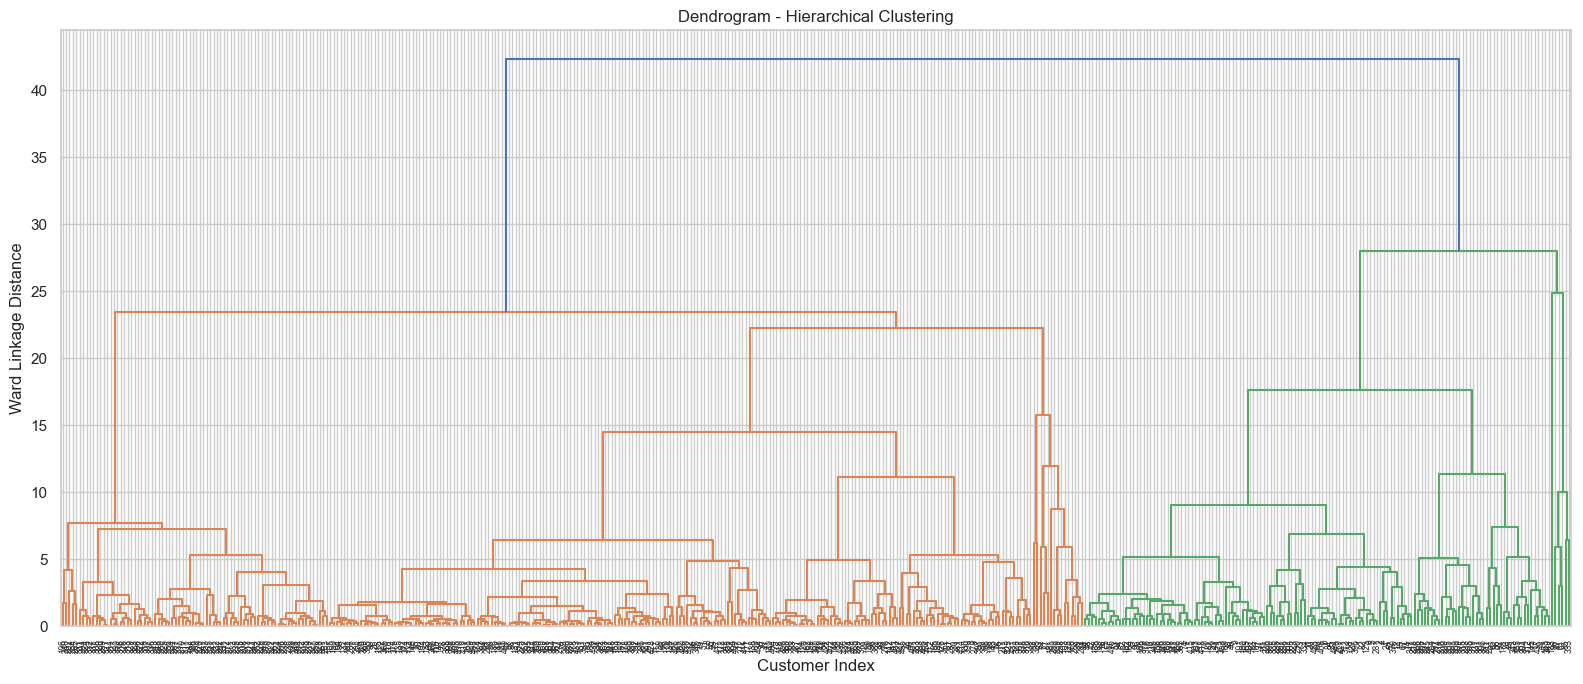

In [19]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(16, 7))

dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=6
)

plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()

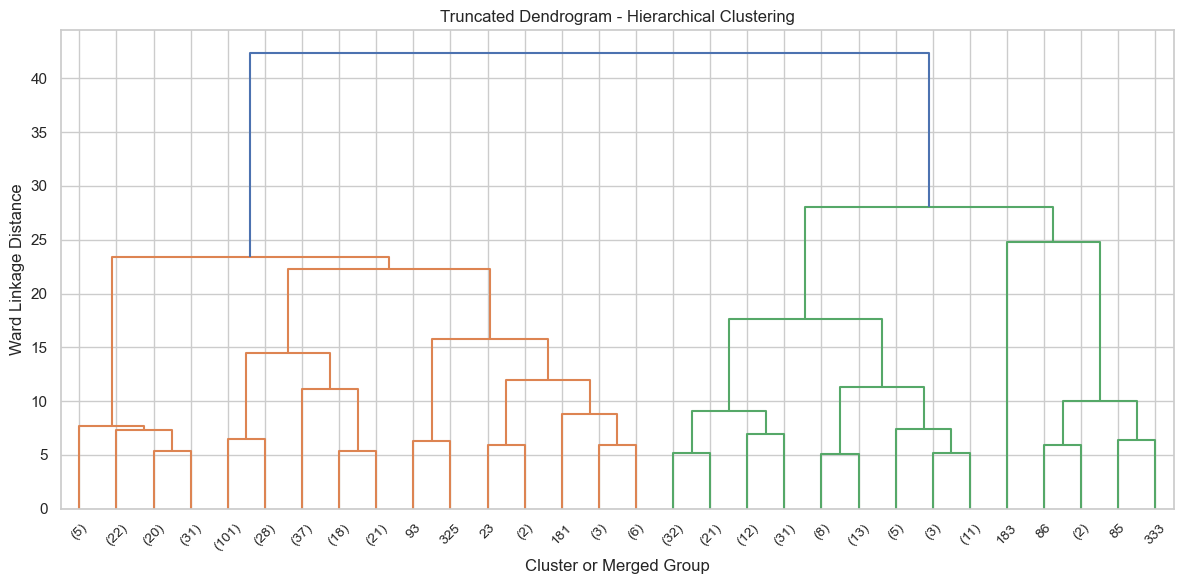

In [22]:
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=45
)

plt.title("Truncated Dendrogram - Hierarchical Clustering")
plt.xlabel("Cluster or Merged Group")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()

In [24]:
from sklearn.decomposition import PCA
import pandas as pd

# Apply PCA with two components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Display explained variance
print(
    "Variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# Create the plotting DataFrame
plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans_Cluster": kmeans_labels.astype(str),
    "Hierarchical_Cluster": hierarchical_labels.astype(str)
})

display(plot_df.head())

Variance explained by the two PCA components: 61.12 %


,PC1,PC2,KMeans_Cluster,Hierarchical_Cluster
0,0.843939,-0.515351,1,6
1,1.062676,-0.484601,1,6
2,1.269141,0.682055,1,6
3,-1.056782,0.610821,0,0
4,0.634030,0.974199,1,6


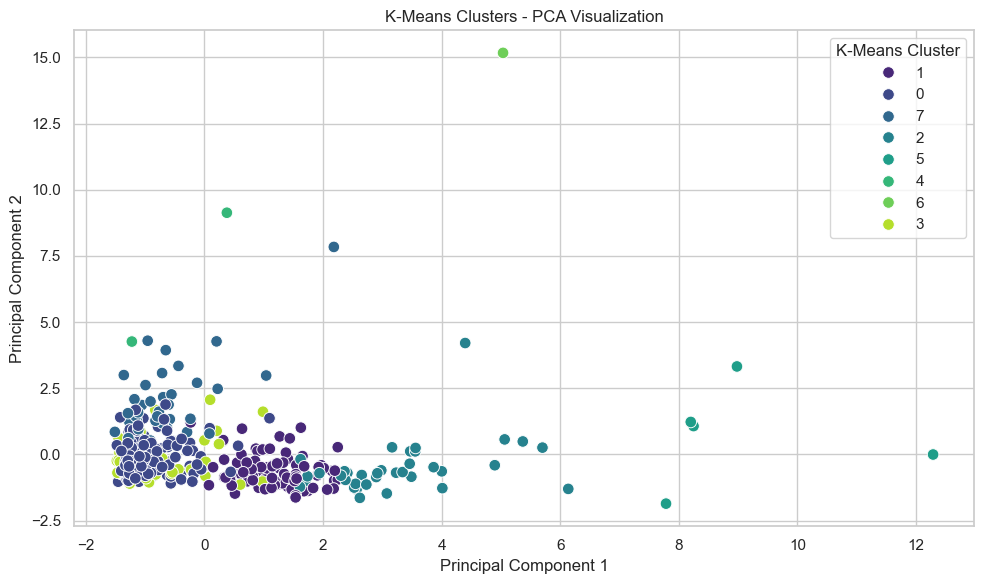

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="viridis",
    s=70
)

plt.title("K-Means Clusters - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="K-Means Cluster")
plt.tight_layout()
plt.show()

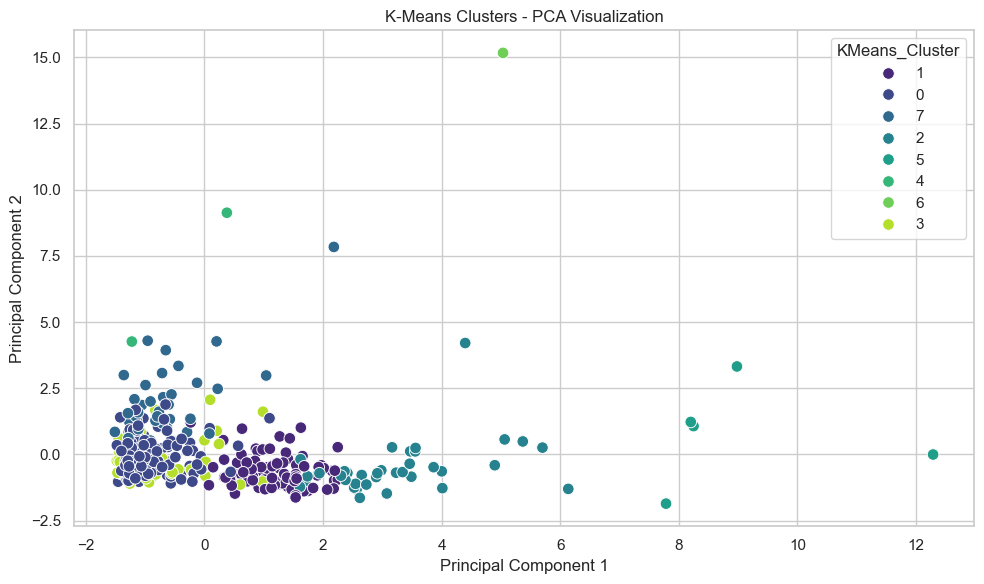

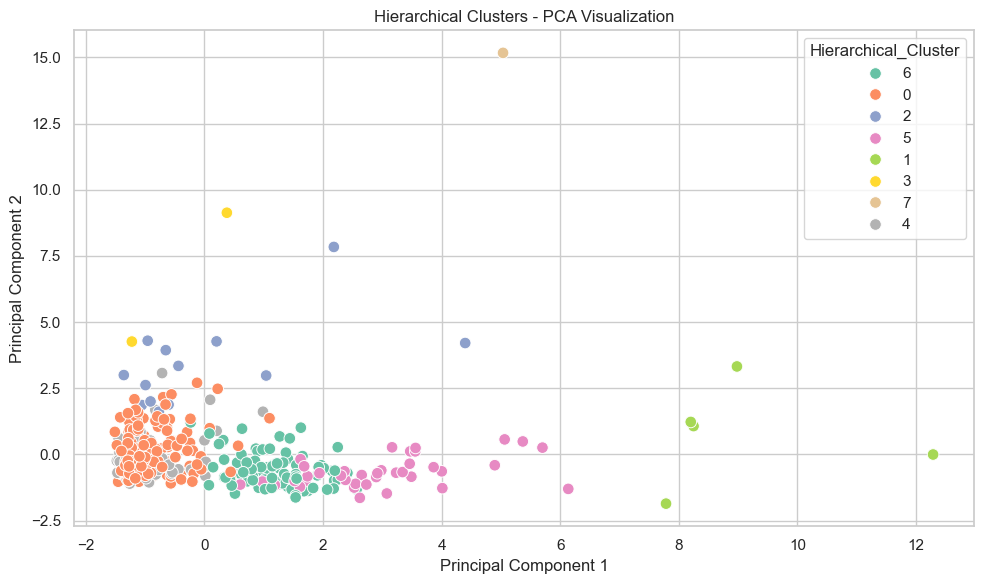

In [26]:
# K-Means cluster visualization
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="viridis",
    s=70
)

plt.title("K-Means Clusters - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

# Hierarchical cluster visualization
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Hierarchical_Cluster",
    palette="Set2",
    s=70
)

plt.title("Hierarchical Clusters - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import silhouette_score
import numpy as np

def evaluate_clustering(X_data, labels, model_name):
    return {
        "Algorithm": model_name,
        "Number of Clusters": len(np.unique(labels)),
        "Silhouette Score": round(
            silhouette_score(X_data, labels), 3
        )
    }

In [28]:
kmeans_results = evaluate_clustering(
    X_scaled,
    kmeans_labels,
    "K-Means"
)

hierarchical_results = evaluate_clustering(
    X_scaled,
    hierarchical_labels,
    "Hierarchical Clustering"
)

evaluation_df = pd.DataFrame([
    kmeans_results,
    hierarchical_results
])

print("Clustering Evaluation Results:")
display(evaluation_df)

Clustering Evaluation Results:


,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,8,0.374
1,Hierarchical Clustering,8,0.354
